# Dataset structure

```
dataset/
├── normal/
│   ├── images/
│   └── masks/
├── lichen/
│   ├── images/
│   └── masks/
├── other/
│   ├── images/
│   └── masks/
```

The notebook will automatically detect this new layout and also support the older `normal_images/lichen_images` naming when needed.


In [1]:
%pip install -q segmentation-models-pytorch albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 1.4 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 53.1 MB/s eta 0:00:0000:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incomp

In [2]:
import os
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_recall_fscore_support,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split

import copy
from skimage.morphology import remove_small_objects

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 384
BATCH_SIZE = 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)


def resolve_dataset_path(base_dir, preferred_path, *legacy_paths):
    for candidate in [base_dir / preferred_path, *[base_dir / legacy for legacy in legacy_paths]]:
        if candidate.exists():
            return candidate
    return base_dir / preferred_path


def find_dataset_root():
    candidates = [
        Path("/kaggle/input/datasets/<kaggle-user>/unet-separate"),
        Path("/kaggle/input/oral-lichen-unet"),
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd() / "dataset",
        Path.cwd().parent / "dataset",
    ]
    for candidate in candidates:
        if (candidate / "normal" / "images").exists() and (candidate / "lichen" / "images").exists():
            return candidate
        if (candidate / "normal_images").exists() and (candidate / "lichen_images").exists():
            return candidate
    return Path.cwd() / "dataset"


DATASET_ROOT = find_dataset_root()
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
NORMAL_IMG_DIR = resolve_dataset_path(DATASET_ROOT, "normal/images", "normal_images")
NORMAL_MASK_DIR = resolve_dataset_path(DATASET_ROOT, "normal/masks", "normal_masks")
LICHEN_IMG_DIR = resolve_dataset_path(DATASET_ROOT, "lichen/images", "lichen_images")
LICHEN_MASK_DIR = resolve_dataset_path(DATASET_ROOT, "lichen/masks", "lichen_masks")
OTHER_IMG_DIR = resolve_dataset_path(DATASET_ROOT, "other/images", "other_images")
OTHER_MASK_DIR = resolve_dataset_path(DATASET_ROOT, "other/masks", "other_masks")

HAS_OTHER_IMAGES = OTHER_IMG_DIR.exists() and any(
    p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    for p in OTHER_IMG_DIR.iterdir()
)
NUM_CLASSES = 3 if HAS_OTHER_IMAGES else 2

print("Paths")
print("  DATASET_ROOT:", DATASET_ROOT)
print("  NORMAL_IMG_DIR:", NORMAL_IMG_DIR)
print("  NORMAL_MASK_DIR:", NORMAL_MASK_DIR)
print("  LICHEN_IMG_DIR:", LICHEN_IMG_DIR)
print("  LICHEN_MASK_DIR:", LICHEN_MASK_DIR)
print("  OTHER_IMG_DIR:", OTHER_IMG_DIR)
print("  OTHER_MASK_DIR:", OTHER_MASK_DIR)
print("  NUM_CLASSES:", NUM_CLASSES)
print("  DEVICE:", DEVICE)
print("  OUTPUT_DIR:", OUTPUT_DIR)


Using device: cuda
Paths
  DATASET_ROOT: /kaggle/input/datasets/<kaggle-user>/unet-separate
  NORMAL_IMG_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/normal/images
  NORMAL_MASK_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/normal/masks
  LICHEN_IMG_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/lichen/images
  LICHEN_MASK_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/lichen/masks
  OTHER_IMG_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/other/images
  OTHER_MASK_DIR: /kaggle/input/datasets/<kaggle-user>/unet-separate/other/masks
  NUM_CLASSES: 3
  DEVICE: cuda
  OUTPUT_DIR: /kaggle/working


In [3]:
class OralLichen4FolderDataset(Dataset):
    def __init__(
        self,
        normal_img_dir,
        lichen_img_dir,
        lichen_mask_dir,
        normal_mask_dir=None,
        other_img_dir=None,
        other_mask_dir=None,
        image_size=IMG_SIZE,
        augment=None,
        include_other=False,
    ):
        self.image_size = image_size
        self.augment = augment
        self.samples = []

        self.normal_img_dir = Path(normal_img_dir) if normal_img_dir is not None else None
        self.lichen_img_dir = Path(lichen_img_dir) if lichen_img_dir is not None else None
        self.lichen_mask_dir = Path(lichen_mask_dir) if lichen_mask_dir is not None else None
        self.normal_mask_dir = Path(normal_mask_dir) if normal_mask_dir is not None else None
        self.other_img_dir = Path(other_img_dir) if other_img_dir is not None else None
        self.other_mask_dir = Path(other_mask_dir) if other_mask_dir is not None else None

        if self.normal_img_dir and self.normal_img_dir.exists():
            for img_path in sorted(self.normal_img_dir.iterdir()):
                if img_path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    mask_path = None
                    if self.normal_mask_dir:
                        candidate = self.normal_mask_dir / f"{img_path.stem}.png"
                        if candidate.exists():
                            mask_path = candidate
                    self.samples.append({"img": img_path, "mask": mask_path, "class": 0})

        if self.lichen_img_dir and self.lichen_img_dir.exists():
            for img_path in sorted(self.lichen_img_dir.iterdir()):
                if img_path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    mask_path = None
                    if self.lichen_mask_dir:
                        candidate = self.lichen_mask_dir / f"{img_path.stem}.png"
                        if candidate.exists():
                            mask_path = candidate
                    self.samples.append({"img": img_path, "mask": mask_path, "class": 1})

        if include_other and self.other_img_dir and self.other_img_dir.exists():
            for img_path in sorted(self.other_img_dir.iterdir()):
                if img_path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    mask_path = None
                    if self.other_mask_dir:
                        candidate = self.other_mask_dir / f"{img_path.stem}.png"
                        if candidate.exists():
                            mask_path = candidate
                    self.samples.append({"img": img_path, "mask": mask_path, "class": 2})

        if len(self.samples) == 0:
            raise ValueError("No segmentation samples found. Check the dataset folders and mask paths.")

    def __len__(self):
        return len(self.samples)

    def _load_mask(self, sample):
        if sample["mask"] is not None and sample["mask"].exists():
            mask = cv2.imread(str(sample["mask"]), cv2.IMREAD_GRAYSCALE)
            if mask is None:
                mask = np.zeros((self.image_size, self.image_size), dtype=np.uint8)
            else:
                mask = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
            # multiply by class index: lichen(1)*1=1, other(2)*1=2, normal(0)*0=0
            return (mask > 0).astype(np.uint8) * sample["class"]

        mask = cv2.imread(str(sample["img"]), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            return np.zeros((self.image_size, self.image_size), dtype=np.uint8)
        mask = cv2.resize(mask, (self.image_size, self.image_size), interpolation=cv2.INTER_NEAREST)
        if sample["class"] == 1:
            return np.ones_like(mask, dtype=np.uint8)
        if sample["class"] == 2:
            return np.full(mask.shape, 2, dtype=np.uint8)
        return np.zeros_like(mask, dtype=np.uint8)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        image = cv2.imread(str(sample["img"]))
        if image is None:
            raise FileNotFoundError(f"Unable to read image: {sample['img']}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.image_size, self.image_size), interpolation=cv2.INTER_LINEAR)

        mask = self._load_mask(sample)

        if self.augment:
            augmented = self.augment(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        if isinstance(image, np.ndarray):
            image = image.transpose(2, 0, 1)
            image = torch.tensor(image, dtype=torch.float32)

        if isinstance(mask, np.ndarray):
            mask = torch.tensor(mask, dtype=torch.long)
        elif isinstance(mask, torch.Tensor):
            mask = mask.long()

        return image, mask


In [4]:
train_transform = A.Compose(
    [
        # ── Geometry ─────────────────────────────────────────────────────────
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.Affine(
            translate_percent={"x": (-0.05, 0.05), "y": (-0.05, 0.05)},
            scale=(0.88, 1.12),
            rotate=(-15, 15),
            p=0.4,
        ),
        A.ElasticTransform(alpha=30, sigma=5, p=0.2),

        # ── Color / brightness ────────────────────────────────────────────────
        A.OneOf(
            [
                A.RandomGamma(gamma_limit=(80, 120), p=0.7),
                A.RandomBrightnessContrast(brightness_limit=0.25, contrast_limit=0.25, p=0.7),
                A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=15, p=0.5),
            ],
            p=0.8,
        ),
        A.CLAHE(clip_limit=(2, 4), tile_grid_size=(8, 8), p=0.4),

        # ── Texture / noise ───────────────────────────────────────────────────
        A.OneOf(
            [
                A.GaussNoise(std_range=(0.01, 0.05), p=0.6),
                A.GaussianBlur(blur_limit=(3, 5), p=0.4),
            ],
            p=0.4,
        ),
        A.Sharpen(alpha=(0.1, 0.3), lightness=(0.9, 1.1), p=0.2),

        # ── Cutout — forces model not to rely on any single region ────────────
        # holes are masked on the IMAGE only, not the mask, so GT labels are preserved
        A.CoarseDropout(
            num_holes_range=(1, 3),
            hole_height_range=(16, 32),
            hole_width_range=(16, 32),
            fill=0,
            p=0.3,
        ),

        # ── Normalise ─────────────────────────────────────────────────────────
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ],
    additional_targets={"mask": "mask"},
)

val_transform = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
], additional_targets={"mask": "mask"})


In [5]:
def build_segmenter(model_name="unet", encoder="efficientnet-b0", pretrained=True):
    if model_name == "unet":
        return smp.Unet(
            encoder_name=encoder,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=NUM_CLASSES,
            decoder_dropout=0.5,
        )
    if model_name == "unetplusplus":
        return smp.UnetPlusPlus(
            encoder_name=encoder,
            encoder_weights="imagenet" if pretrained else None,
            in_channels=3,
            classes=NUM_CLASSES,
            decoder_dropout=0.5,
            decoder_attention_type="scse",
        )
    raise ValueError(f"Unknown segmentation model: {model_name}")


In [6]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS    = 5
BATCH_SIZE = 4   # reduced from 8 - IMG_SIZE 384 uses ~2.25x the memory of 256

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def collect_samples():
    """Return flat list of {img, mask, class} dicts for all three classes."""
    samples = []
    dirs = [
        (NORMAL_IMG_DIR,  NORMAL_MASK_DIR,  0),
        (LICHEN_IMG_DIR,  LICHEN_MASK_DIR,  1),
    ]
    if HAS_OTHER_IMAGES:
        dirs.append((OTHER_IMG_DIR, OTHER_MASK_DIR, 2))

    for img_dir, mask_dir, cls in dirs:
        for img_path in sorted(Path(img_dir).iterdir()):
            if img_path.suffix.lower() not in EXTS:
                continue
            mask_path = Path(mask_dir) / f"{img_path.stem}.png"
            samples.append({
                "img":   img_path,
                "mask":  mask_path if mask_path.exists() else None,
                "class": cls,
            })
    return samples


def make_fold_loaders(all_samples, train_idx, val_idx):
    train_s = [all_samples[i] for i in train_idx]
    val_s   = [all_samples[i] for i in val_idx]

    train_ds = OralLichen4FolderDataset(
        normal_img_dir=NORMAL_IMG_DIR, lichen_img_dir=LICHEN_IMG_DIR,
        lichen_mask_dir=LICHEN_MASK_DIR, normal_mask_dir=NORMAL_MASK_DIR,
        other_img_dir=OTHER_IMG_DIR, other_mask_dir=OTHER_MASK_DIR,
        image_size=IMG_SIZE, augment=train_transform, include_other=HAS_OTHER_IMAGES,
    )
    val_ds = OralLichen4FolderDataset(
        normal_img_dir=NORMAL_IMG_DIR, lichen_img_dir=LICHEN_IMG_DIR,
        lichen_mask_dir=LICHEN_MASK_DIR, normal_mask_dir=NORMAL_MASK_DIR,
        other_img_dir=OTHER_IMG_DIR, other_mask_dir=OTHER_MASK_DIR,
        image_size=IMG_SIZE, augment=val_transform, include_other=HAS_OTHER_IMAGES,
    )
    train_subset = torch.utils.data.Subset(train_ds, train_idx)
    val_subset   = torch.utils.data.Subset(val_ds,   val_idx)

    train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=2, pin_memory=True)
    return train_subset, val_subset, train_loader, val_loader


all_samples = collect_samples()
all_labels  = np.array([s["class"] for s in all_samples])

skf    = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits = list(skf.split(all_samples, all_labels))

print(f"Total samples : {len(all_samples)}")
print(f"  normal={sum(all_labels==0)}  lichen={sum(all_labels==1)}  other={sum(all_labels==2)}")
print(f"Folds  : {N_FOLDS}  (~{len(splits[0][0])} train / ~{len(splits[0][1])} val each)")


Total samples : 969
  normal=357  lichen=302  other=310
Folds  : 5  (~775 train / ~194 val each)


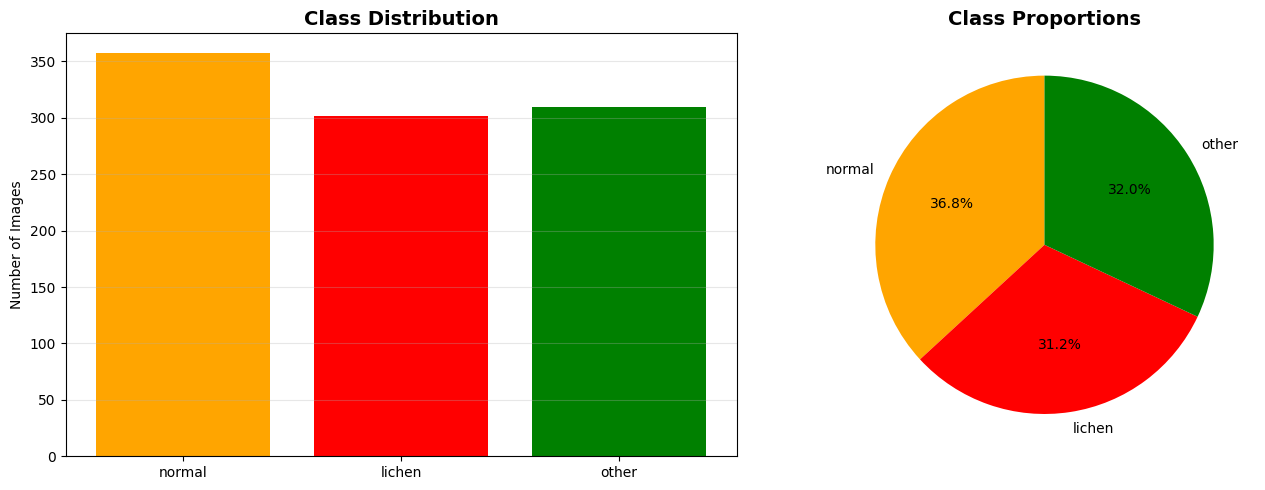

In [7]:
# Visualize class distribution before training
class_names  = ["normal", "lichen"] + (["other"] if HAS_OTHER_IMAGES else [])
class_colors = ["orange", "red", "green"][:len(class_names)]
class_counts = {name: int((all_labels == i).sum()) for i, name in enumerate(class_names)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_counts.keys(), class_counts.values(), color=class_colors)
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Images')
axes[0].grid(axis='y', alpha=0.3)

axes[1].pie(class_counts.values(), labels=class_counts.keys(), autopct='%1.1f%%',
            colors=class_colors, startangle=90)
axes[1].set_title('Class Proportions', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


In [8]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score, accuracy_score

EPOCHS                = 60
LR                    = 5e-4
WEIGHT_DECAY          = 2e-3
ENCODER_FREEZE_EPOCHS = 5
PATIENCE              = 15

experiment_config = [
    {"name": "UNet",          "arch": "unet"},
    # {"name": "UNet++ + scSE", "arch": "unetplusplus"},
]


class HybridSegmentationLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
        # TverskyLoss(alpha=0.3, beta=0.7): penalises FP (alpha) less, FN (beta) more
        # compared to Dice (alpha=beta=0.5). Raises precision without sacrificing recall.
        self.tversky = smp.losses.TverskyLoss(
            mode="multiclass", from_logits=True, alpha=0.3, beta=0.7
        )

    def forward(self, logits, target):
        return self.ce(logits, target) + self.tversky(logits, target)


def compute_class_weights(dataset, num_classes=NUM_CLASSES):
    counts  = np.zeros(num_classes, dtype=np.float64)
    ds      = dataset.dataset if isinstance(dataset, torch.utils.data.Subset) else dataset
    indices = dataset.indices  if isinstance(dataset, torch.utils.data.Subset) else range(len(ds))
    for idx in indices:
        _, mask = ds[idx]
        hist, _ = np.histogram(mask.cpu().numpy().astype(np.int64),
                               bins=np.arange(num_classes + 1))
        counts += hist
    weights = counts.sum() / (num_classes * counts + 1e-8)
    return torch.tensor(weights, dtype=torch.float32)


def dice_score_per_class(preds, target, num_classes=NUM_CLASSES, eps=1e-7):
    scores = []
    for cls in range(num_classes):
        p = (preds == cls).float(); t = (target == cls).float()
        inter = (p * t).sum(dim=(1, 2))
        union = p.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
        valid = union > 0
        scores.append(((2*inter[valid]+eps)/(union[valid]+eps)).mean().item() if valid.any() else float('nan'))
    return scores


def iou_score_per_class(preds, target, num_classes=NUM_CLASSES, eps=1e-7):
    scores = []
    for cls in range(num_classes):
        p = (preds == cls); t = (target == cls)
        inter = (p & t).sum(dim=(1,2)).float()
        union = (p | t).sum(dim=(1,2)).float()
        scores.append(((inter+eps)/(union+eps)).mean().item())
    return scores


def compute_lichen_metrics(y_pred, y_true, eps=1e-8):
    y_pred = y_pred.flatten().astype(np.int64)
    y_true = y_true.flatten().astype(np.int64)
    yp = (y_pred == 1).astype(np.int64)
    yt = (y_true == 1).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    sens = tp / (tp + fn + eps)
    spec = tn / (tn + fp + eps)
    prec = tp / (tp + fp + eps)
    f1   = 2 * prec * sens / (prec + sens + eps)
    return {"tp":int(tp),"fp":int(fp),"fn":int(fn),"tn":int(tn),
            "sensitivity":float(sens),"specificity":float(spec),
            "precision":float(prec),"f1":float(f1)}


class LichenEarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=1e-4):
        self.patience  = patience
        self.min_delta = min_delta
        self.best      = -float("inf")
        self.bad       = 0

    def step(self, score):
        if score > self.best + self.min_delta:
            self.best = score; self.bad = 0; return False
        self.bad += 1
        return self.bad >= self.patience


def train_epoch_segmenter(model, loader, optimizer, criterion, device):
    model.train()
    total = 0.0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(imgs), masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * imgs.size(0)
    return total / len(loader.dataset)


def validate_segmenter(model, loader, criterion, device):
    model.eval()
    total = 0.0
    all_dice, all_iou, y_pred, y_true = [], [], [], []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            total += criterion(logits, masks).item() * imgs.size(0)
            preds = logits.argmax(dim=1)
            all_dice.append(dice_score_per_class(preds, masks))
            all_iou.append(iou_score_per_class(preds, masks))
            y_pred.append(preds.cpu().numpy().reshape(-1))
            y_true.append(masks.cpu().numpy().reshape(-1))
    mean_dice = np.where(np.isnan(np.nanmean(all_dice, axis=0)), 0.0,
                         np.nanmean(all_dice, axis=0)).tolist()
    mean_iou  = np.mean(all_iou, axis=0).tolist()
    bin_met   = compute_lichen_metrics(np.concatenate(y_pred), np.concatenate(y_true))
    return total / len(loader.dataset), mean_dice, mean_iou, float(mean_dice[1]), bin_met


def run_fold(fold_idx, config, train_subset, val_subset, train_loader, val_loader, device):
    print(f"\n  Fold {fold_idx}  train={len(train_subset)}  val={len(val_subset)}")

    segmenter = build_segmenter(config["arch"]).to(device)

    for p in segmenter.encoder.parameters():
        p.requires_grad = False

    class_weights = compute_class_weights(train_subset).to(device)
    criterion     = HybridSegmentationLoss(class_weights)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, segmenter.parameters()),
        lr=LR, weight_decay=WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    stopper   = LichenEarlyStopping()

    history    = []
    best_f1    = -1.0
    best_state = None

    for epoch in range(1, EPOCHS + 1):
        if epoch == ENCODER_FREEZE_EPOCHS + 1:
            for p in segmenter.encoder.parameters():
                p.requires_grad = True
            optimizer = torch.optim.AdamW(segmenter.parameters(), lr=LR/5, weight_decay=WEIGHT_DECAY)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=EPOCHS - epoch, eta_min=1e-6)
            print(f"    [ep {epoch}] Encoder unfrozen  lr={LR/5:.1e}")

        t_loss = train_epoch_segmenter(segmenter, train_loader, optimizer, criterion, device)
        v_loss, v_dice, v_iou, _, bm = validate_segmenter(segmenter, val_loader, criterion, device)
        scheduler.step()

        row = dict(fold=fold_idx, epoch=epoch,
                   train_loss=t_loss, val_loss=v_loss,
                   lichen_dice=v_dice[1], lichen_f1=bm["f1"],
                   precision=bm["precision"],
                   sensitivity=bm["sensitivity"], specificity=bm["specificity"])
        history.append(row)

        improved = bm["f1"] > best_f1 + 1e-4
        if improved:
            best_f1    = bm["f1"]
            best_state = copy.deepcopy(segmenter.state_dict())
            torch.save(best_state, OUTPUT_DIR / f"{config['name'].replace(' ','_')}_fold{fold_idx}_best.pth")

        print(f"    ep {epoch:3d}  t={t_loss:.4f}  v={v_loss:.4f}  "
              f"dice={v_dice[1]:.3f}  f1={bm['f1']:.4f}  "
              f"prec={bm['precision']:.3f}  sens={bm['sensitivity']:.3f}"
              f"{'  *' if improved else ''}")

        if stopper.step(bm["f1"]):
            print(f"    Early stop — best F1={best_f1:.4f}")
            break

    if best_state is not None:
        segmenter.load_state_dict(best_state)
    return segmenter, best_f1, pd.DataFrame(history)

print("Training helpers defined.")


Training helpers defined.



Architecture: UNet

  Fold 0  train=775  val=194


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

    ep   1  t=1.8460  v=1.5477  dice=0.186  f1=0.3996  prec=0.292  sens=0.635  *
    ep   2  t=1.7621  v=1.5341  dice=0.107  f1=0.2435  prec=0.192  sens=0.334
    ep   3  t=1.7226  v=1.5322  dice=0.191  f1=0.4237  prec=0.311  sens=0.665  *
    ep   4  t=1.7101  v=1.5191  dice=0.191  f1=0.4402  prec=0.344  sens=0.610  *
    ep   5  t=1.7039  v=1.5179  dice=0.204  f1=0.4257  prec=0.289  sens=0.811
    [ep 6] Encoder unfrozen  lr=1.0e-04
    ep   6  t=1.6925  v=1.4994  dice=0.237  f1=0.5128  prec=0.377  sens=0.802  *
    ep   7  t=1.6601  v=1.4743  dice=0.226  f1=0.4567  prec=0.314  sens=0.839
    ep   8  t=1.6213  v=1.4035  dice=0.215  f1=0.5673  prec=0.470  sens=0.716  *
    ep   9  t=1.5882  v=1.4088  dice=0.210  f1=0.5791  prec=0.469  sens=0.758  *
    ep  10  t=1.5820  v=1.4202  dice=0.226  f1=0.5419  prec=0.394  sens=0.866
    ep  11  t=1.5715  v=1.5034  dice=0.232  f1=0.4910  prec=0.334  sens=0.926
    ep  12  t=1.5377  v=1.4706  dice=0.259  f1=0.5509  prec=0.397  sens=0.901
    ep

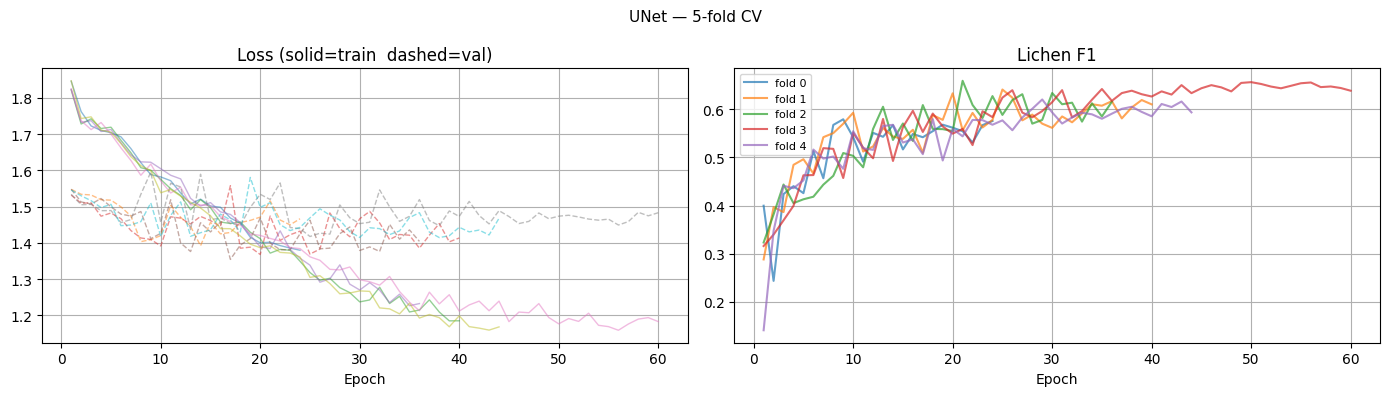

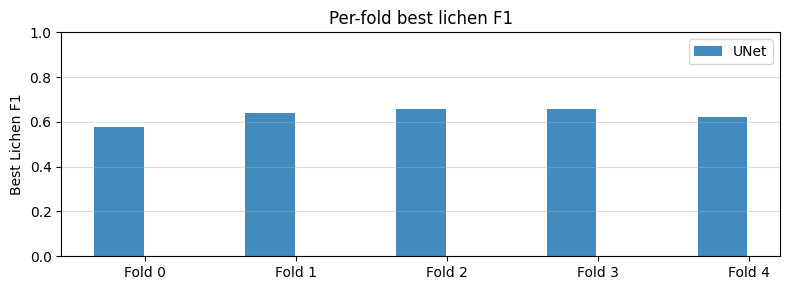

In [9]:
import torch.nn.functional as F

# ── Run 5-fold CV for each architecture ───────────────────────────────────────
cv_results  = []   # one row per (arch, fold)
cv_history  = []   # epoch-level rows for plotting

fold_models = {}   # fold_models[arch_name][fold_idx] = trained model

for config in experiment_config:
    print(f"\n{'='*60}")
    print(f"Architecture: {config['name']}")
    print(f"{'='*60}")

    fold_models[config["name"]] = {}

    for fold_idx, (train_idx, val_idx) in enumerate(splits):
        train_subset, val_subset, train_loader, val_loader = \
            make_fold_loaders(all_samples, train_idx, val_idx)

        model, best_f1, hist_df = run_fold(
            fold_idx, config,
            train_subset, val_subset,
            train_loader, val_loader,
            DEVICE,
        )
        fold_models[config["name"]][fold_idx] = model
        cv_results.append({"arch": config["name"], "fold": fold_idx, "best_f1": best_f1})
        cv_history.append(hist_df)

# ── Summary table ─────────────────────────────────────────────────────────────
results_df = pd.DataFrame(cv_results)
summary    = results_df.groupby("arch")["best_f1"].agg(["mean","std","min","max"]).round(4)
print("\n\nCV Summary")
print(summary.to_string())

# ── Save metrics ──────────────────────────────────────────────────────────────
results_df.to_csv(OUTPUT_DIR / "cv_results.csv", index=False)
summary.to_csv(OUTPUT_DIR / "cv_summary.csv")
all_history_tmp = pd.concat(cv_history, ignore_index=True)
all_history_tmp.to_csv(OUTPUT_DIR / "cv_history.csv", index=False)

# ── Plot: per-fold F1 curves for each arch ────────────────────────────────────
all_history = pd.concat(cv_history, ignore_index=True)

for config in experiment_config:
    arch_name = config["name"]
    arch_hist = all_history[all_history["fold"].isin(range(N_FOLDS))]
    # filter to rows that came from this arch (history was appended in arch order)
    arch_rows = all_history[
        all_history.index.isin(
            all_history[all_history["fold"] < N_FOLDS].index[:len(all_history)//len(experiment_config)]
        )
    ]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f"{arch_name} — 5-fold CV", fontsize=11)

    for fold_idx in range(N_FOLDS):
        fold_h = all_history[
            (all_history["fold"] == fold_idx)
        ].reset_index(drop=True)
        if fold_h.empty:
            continue
        ep = fold_h["epoch"]
        axes[0].plot(ep, fold_h["train_loss"], alpha=0.5, linewidth=1)
        axes[0].plot(ep, fold_h["val_loss"],   alpha=0.5, linewidth=1, linestyle="--")
        axes[1].plot(ep, fold_h["lichen_f1"],  alpha=0.7, linewidth=1.5, label=f"fold {fold_idx}")

    axes[0].set_title("Loss (solid=train  dashed=val)"); axes[0].set_xlabel("Epoch"); axes[0].grid(True)
    axes[1].set_title("Lichen F1"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8); axes[1].grid(True)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"training_curves_{arch_name.replace(' ','_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ── Per-fold F1 bar chart ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 3))
for i, config in enumerate(experiment_config):
    arch_res = results_df[results_df["arch"] == config["name"]]
    x = np.arange(N_FOLDS) + i * 0.35
    ax.bar(x, arch_res["best_f1"].values, width=0.33, label=config["name"], alpha=0.85)
ax.set_xticks(np.arange(N_FOLDS) + 0.175)
ax.set_xticklabels([f"Fold {k}" for k in range(N_FOLDS)])
ax.set_ylabel("Best Lichen F1"); ax.set_ylim(0, 1); ax.legend(); ax.grid(axis="y", alpha=0.4)
ax.set_title("Per-fold best lichen F1")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_fold_f1.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
from skimage.measure import label
import itertools

def object_confusion_metrics(gt_mask, pred_mask, min_iou=0.3):
    gt_labels = label(gt_mask == 1)
    pred_labels = label(pred_mask == 1)
    gt_ids = np.unique(gt_labels)
    pred_ids = np.unique(pred_labels)
    gt_ids = gt_ids[gt_ids != 0]
    pred_ids = pred_ids[pred_ids != 0]

    if len(gt_ids) == 0 and len(pred_ids) == 0:
        return {"tp": 0, "fp": 0, "fn": 0, "matched": []}

    iou_matrix = np.zeros((len(gt_ids), len(pred_ids)), dtype=np.float32)
    for i, gt_id in enumerate(gt_ids):
        gt_obj = gt_labels == gt_id
        for j, pred_id in enumerate(pred_ids):
            pred_obj = pred_labels == pred_id
            inter = np.logical_and(gt_obj, pred_obj).sum()
            union = np.logical_or(gt_obj, pred_obj).sum()
            iou_matrix[i, j] = inter / (union + 1e-8) if union > 0 else 0.0

    match_pairs = []
    for i, j in itertools.product(range(len(gt_ids)), range(len(pred_ids))):
        if iou_matrix[i, j] >= min_iou:
            match_pairs.append((iou_matrix[i, j], i, j))
    match_pairs.sort(reverse=True, key=lambda x: x[0])

    matched_gt = set()
    matched_pred = set()
    matches = []
    for iou, i, j in match_pairs:
        if i in matched_gt or j in matched_pred:
            continue
        matched_gt.add(i)
        matched_pred.add(j)
        matches.append((gt_ids[i], pred_ids[j], float(iou)))

    tp = len(matches)
    fn = len(gt_ids) - tp
    fp = len(pred_ids) - tp
    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "matched": matches,
    }

def evaluate_object_confusion(model, loader, device, min_iou=0.3):
    model.eval()
    counts = {"tp": 0, "fp": 0, "fn": 0}
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            preds = logits.argmax(dim=1).cpu().numpy()
            gt = masks.cpu().numpy()
            for b in range(images.size(0)):
                gt_mask = (gt[b] == 1).astype(np.uint8)
                pred_mask = (preds[b] == 1).astype(np.uint8)
                obj_metrics = object_confusion_metrics(gt_mask, pred_mask, min_iou=min_iou)
                counts["tp"] += obj_metrics["tp"]
                counts["fp"] += obj_metrics["fp"]
                counts["fn"] += obj_metrics["fn"]

    precision = counts["tp"] / (counts["tp"] + counts["fp"] + 1e-8)
    recall = counts["tp"] / (counts["tp"] + counts["fn"] + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    return {
        "tp": counts["tp"],
        "fp": counts["fp"],
        "fn": counts["fn"],
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

# Example usage:
# model = build_segmenter(experiment_config[-1]["arch"]).to(DEVICE)
# model.load_state_dict(torch.load(f"{experiment_config[-1]["name"].replace(" ", "_")}_best_lichen.pth", map_location=DEVICE))
# obj_conf = evaluate_object_confusion(model, val_loader, DEVICE, min_iou=0.3)
# print(obj_conf)


In [ ]:
def make_error_overlay(image, mask, pred, alpha=0.4):
    image = image.copy()
    if image.dtype != np.uint8:
        image = (np.clip(image, 0, 1) * 255).astype(np.uint8)

    tp = (mask == 1) & (pred == 1)
    fp = (mask == 0) & (pred == 1)
    fn = (mask == 1) & (pred == 0)

    overlay = image.copy()
    overlay[tp] = [0, 255, 0]
    overlay[fp] = [255, 0, 0]
    overlay[fn] = [0, 0, 255]

    return cv2.addWeighted(image, 1.0 - alpha, overlay, alpha, 0)


def show_segmentation_errors(model, loader, device, n_samples=3):
    model.eval()
    shown = 0
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            preds = logits.argmax(dim=1).cpu().numpy()
            for idx in range(images.size(0)):
                img = images[idx].cpu().permute(1, 2, 0).numpy()
                img = (img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]))
                img = np.clip(img, 0, 1)
                img = (img * 255).astype(np.uint8)
                gt_mask = masks[idx].cpu().numpy().astype(np.uint8)
                pr_mask = preds[idx].astype(np.uint8)
                overlay = make_error_overlay(img, gt_mask, pr_mask)
                plt.figure(figsize=(10, 5))
                plt.imshow(overlay)
                plt.title('TP=green | FP=red | FN=blue')
                plt.axis('off')
                plt.show()ensemble_predictions.png
                shown += 1
                if shown >= n_samples:
                    return


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# ENSEMBLE INFERENCE  —  average softmax across all fold checkpoints
# Red = Lichen  |  Green = Other  |  No tint = Normal
# ═══════════════════════════════════════════════════════════════════════════════
_PALETTE = {
    1: np.array([220,  50,  50], dtype=np.uint8),  # lichen – red
    2: np.array([ 50, 200,  80], dtype=np.uint8),  # other  – green
}
_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def _load_fold_models(config, n_folds=N_FOLDS):
    """Load best checkpoint for every fold of a given architecture."""
    models = []
    for k in range(n_folds):
        pth = f"{config['name'].replace(' ', '_')}_fold{k}_best.pth"
        if not os.path.exists(pth):
            print(f"  [warn] not found: {pth}")
            continue
        m = build_segmenter(config["arch"]).to(DEVICE)
        m.load_state_dict(torch.load(pth, map_location=DEVICE))
        m.eval()
        models.append(m)
    return models


def _infer_ensemble(models, img_path):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # resize to model input size BEFORE transform so pred and img_disp match
    img_disp = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    t = val_transform(image=img_disp)["image"].unsqueeze(0).to(DEVICE)
    probs_sum = None
    with torch.no_grad():
        for m in models:
            p = torch.softmax(m(t), dim=1).squeeze(0).cpu()  # C×H×W
            probs_sum = p if probs_sum is None else probs_sum + p
    avg  = probs_sum / len(models)
    pred = avg.argmax(dim=0).numpy().astype(np.uint8)  # IMG_SIZE×IMG_SIZE
    return img_disp, pred


def _overlay(img, pred, alpha=0.45):
    out = img.copy()
    for cls, color in _PALETTE.items():
        m = pred == cls
        if m.any():
            out[m] = (img[m] * (1 - alpha) + color * alpha).astype(np.uint8)
    return out


# ── 1. Load ensemble for each architecture ────────────────────────────────────
print("Loading fold checkpoints ...")
_eval_ensembles = {}
for cfg in experiment_config:
    models = _load_fold_models(cfg)
    if models:
        _eval_ensembles[cfg["name"]] = models
        print(f"  {cfg['name']:25s}  {len(models)} folds loaded")

# ── 2. Collect sample images ──────────────────────────────────────────────────
_N = 10
_class_dirs = [("lichen", LICHEN_IMG_DIR), ("normal", NORMAL_IMG_DIR)]
if HAS_OTHER_IMAGES:
    _class_dirs.append(("other", OTHER_IMG_DIR))

_samples = []
for cls_name, img_dir in _class_dirs:
    paths = sorted(p for p in Path(img_dir).iterdir() if p.suffix.lower() in _EXTS)
    _samples.extend((cls_name, p) for p in paths[:_N])
print(f"\nRunning inference on {len(_samples)} sample images ...")

# ── 3. Inference ──────────────────────────────────────────────────────────────
_arch_names = list(_eval_ensembles.keys())
_rows = []
for cls_name, img_path in _samples:
    row = {"cls": cls_name, "path": img_path}
    for arch_name, models in _eval_ensembles.items():
        img_rgb, pred = _infer_ensemble(models, img_path)
        row["img"] = img_rgb
        row[arch_name] = pred
    _rows.append(row)

# ── 4. Plot ───────────────────────────────────────────────────────────────────
_n_cols = 1 + len(_arch_names)
fig, axes = plt.subplots(len(_rows), _n_cols,
                         figsize=(4.5 * _n_cols, 3.5 * len(_rows)), squeeze=False)
fig.suptitle("Ensemble predictions  (Red=Lichen | Green=Other | no tint=Normal)",
             fontsize=11, y=1.005)

for r, row in enumerate(_rows):
    axes[r, 0].imshow(row["img"])
    axes[r, 0].set_title(f"[{row['cls'].upper()}]  {row['path'].stem}", fontsize=8)
    axes[r, 0].axis("off")
    for c, arch_name in enumerate(_arch_names, start=1):
        pred = row[arch_name]
        vis  = _overlay(row["img"], pred)
        n_folds_loaded = len(_eval_ensembles[arch_name])
        lbl = (f"{arch_name} ({n_folds_loaded}-fold ensemble)\n"
               f"Lichen {(pred==1).mean()*100:.1f}%")
        if HAS_OTHER_IMAGES:
            lbl += f"  Other {(pred==2).mean()*100:.1f}%"
        axes[r, c].imshow(vis); axes[r, c].set_title(lbl, fontsize=8); axes[r, c].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ensemble_predictions.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ROC/AUC and confusion matrix for segmentation models — out-of-fold validation predictions
# (each sample is scored by the fold checkpoint that never trained on it, then pooled)

def evaluate_segmentation_roc_confusion(model, loader, device):
    model.eval()
    all_probs = []
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy().reshape(-1)
            preds = logits.argmax(dim=1).cpu().numpy().reshape(-1)
            labels = masks.cpu().numpy().reshape(-1)
            all_probs.append(probs)
            all_preds.append(preds)
            all_labels.append(labels)
    return np.concatenate(all_probs), np.concatenate(all_preds), np.concatenate(all_labels)


def collect_oof_predictions(config):
    """Out-of-fold predictions across all 5 folds for one architecture."""
    probs_list, preds_list, labels_list = [], [], []
    for fold_idx, (train_idx, val_idx) in enumerate(splits):
        ckpt = OUTPUT_DIR / f"{config['name'].replace(' ', '_')}_fold{fold_idx}_best.pth"
        if not ckpt.exists():
            print(f"  [warn] missing checkpoint: {ckpt}")
            continue
        _, _, _, fold_val_loader = make_fold_loaders(all_samples, train_idx, val_idx)
        model = build_segmenter(config["arch"], pretrained=False).to(DEVICE)
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        probs, preds, labels = evaluate_segmentation_roc_confusion(model, fold_val_loader, DEVICE)
        probs_list.append(probs); preds_list.append(preds); labels_list.append(labels)
    return np.concatenate(probs_list), np.concatenate(preds_list), np.concatenate(labels_list)


plt.figure(figsize=(8, 6))
_roc_results = {}
for config in experiment_config:
    y_prob, y_pred, y_true = collect_oof_predictions(config)
    y_true_bin = (y_true == 1).astype(np.int32)
    if len(np.unique(y_true_bin)) > 1:
        fpr, tpr, _ = roc_curve(y_true_bin, y_prob)
        auc_score = roc_auc_score(y_true_bin, y_prob)
    else:
        fpr, tpr, auc_score = np.array([0., 1.]), np.array([0., 1.]), float('nan')
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    _roc_results[config['name']] = (fpr, tpr, auc_score, cm)
    plt.plot(fpr, tpr, label=f"{config['name']} (AUC={auc_score:.4f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', alpha=0.8)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Out-of-fold ROC Curve — Lichen vs Rest (pixel-level)')
plt.legend(loc='lower right')
plt.grid(True)
plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()

_cls_labels = ['Normal', 'Lichen', 'Other'][:NUM_CLASSES]
for name, (fpr, tpr, auc_score, cm) in _roc_results.items():
    print(f"Model: {name} | AUC: {auc_score:.4f}")
    print('Confusion matrix (true labels rows, predicted columns):')
    print(cm)
    fig, ax = plt.subplots(figsize=(4, 4))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(name)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(_cls_labels)
    ax.set_yticklabels(_cls_labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
            ax.text(j, i, cm[i, j], ha='center', va='center', color=color)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"confusion_matrix_{name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()


In [ ]:
def save_validation_overlays(model, val_loader, out_dir, device):
    os.makedirs(out_dir, exist_ok=True)
    model.eval()

    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])

    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_loader):
            images = images.to(device)
            masks = masks.to(device)
            logits = model(images)
            preds_np = logits.argmax(dim=1).detach().cpu().numpy()

            images_np = images.detach().cpu().numpy()
            masks_np = masks.detach().cpu().numpy()

            for i in range(images_np.shape[0]):
                img = images_np[i].transpose(1, 2, 0)
                img = np.clip(img * std + mean, 0, 1)   # reverse A.Normalize (was: broken min-max stretch)
                img_rgb = (img * 255).astype(np.uint8)
                img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

                gt_mask = (masks_np[i] > 0).astype(np.uint8) * 255
                pred_mask = (preds_np[i] > 0).astype(np.uint8) * 255

                overlay_pred = img_bgr.copy()
                overlay_pred[pred_mask == 255] = [0, 0, 255]

                blended = cv2.addWeighted(img_bgr, 0.7, overlay_pred, 0.3, 0)

                base_name = f"val_{batch_idx}_{i}"
                cv2.imwrite(os.path.join(out_dir, base_name + "_image.png"), img_bgr)
                cv2.imwrite(os.path.join(out_dir, base_name + "_gt.png"), gt_mask)
                cv2.imwrite(os.path.join(out_dir, base_name + "_pred.png"), pred_mask)
                cv2.imwrite(os.path.join(out_dir, base_name + "_overlay.png"), blended)

# Example usage after training:
# save_validation_overlays(model, val_loader, "val_overlays", device)


In [ ]:
# Manual batch verification — run after training, once best.pth checkpoints exist.
# Cheap: one forward pass over a single fold's validation set (no training).
ARCH_NAME = "UNet"          # must match a "name" in experiment_config
ARCH_KEY  = "unet"          # must match the corresponding "arch"
FOLD_TO_VERIFY = 0

ckpt_path = OUTPUT_DIR / f"{ARCH_NAME.replace(' ','_')}_fold{FOLD_TO_VERIFY}_best.pth"
train_idx, val_idx = splits[FOLD_TO_VERIFY]
_, _, _, val_loader = make_fold_loaders(all_samples, train_idx, val_idx)

verify_model = build_segmenter(ARCH_KEY).to(DEVICE)
verify_model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

save_validation_overlays(
    verify_model, val_loader,
    OUTPUT_DIR / "val_overlays" / f"{ARCH_NAME.replace(' ','_')}_fold{FOLD_TO_VERIFY}",
    DEVICE,
)
print("Saved batch verification overlays for", ARCH_NAME, "fold", FOLD_TO_VERIFY)


In [ ]:
# Manual batch verification — run after training, once best.pth checkpoints exist.
# Cheap: one forward pass over a single fold's validation set (no training).
ARCH_NAME = "UNet"          # must match a "name" in experiment_config
ARCH_KEY  = "unet"          # must match the corresponding "arch"
FOLD_TO_VERIFY = 0

ckpt_path = OUTPUT_DIR / f"{ARCH_NAME.replace(' ','_')}_fold{FOLD_TO_VERIFY}_best.pth"
train_idx, val_idx = splits[FOLD_TO_VERIFY]
_, _, _, val_loader = make_fold_loaders(all_samples, train_idx, val_idx)

verify_model = build_segmenter(ARCH_KEY).to(DEVICE)
verify_model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

save_validation_overlays(
    verify_model, val_loader,
    OUTPUT_DIR / "val_overlays" / f"{ARCH_NAME.replace(' ','_')}_fold{FOLD_TO_VERIFY}",
    DEVICE,
)
print("Saved batch verification overlays for", ARCH_NAME, "fold", FOLD_TO_VERIFY)


In [ ]:
! rm -rf val_overlays.tar

In [ ]:
!tar -cvf val_overlays.tar -C val_overlays .